# Text Mining: Skills, Topics and Clusters

Input: `data/processed/career_market_preprocessed.csv` (job postings, 10 roles) and the skill list in
`config/review2_skills.json`.

Output: tables and figures in `reports/text_mining/`, the contract file `data/review2/skill_demand.csv`
and the fitted clustering in `models/text_mining_clusters.pkl`.

**Objective.** Identify which technical skills employers name in job postings, how the skills and the
wording group the postings, and whether a description identifies its role, while being clear about what
the 500-character limit prevents us from concluding. The original goal also covered employer demand shares
and skill gaps. It was narrowed because of that limit (section 12), and the same change is recorded in
`data/processed/dataset_design.md`, section 14.

| Section | Method |
|---|---|
| 1 | Data selection and profile |
| 2-4 | Skill extraction, demand, co-occurrence |
| 5 | Term-document matrix and TF-IDF |
| 6 | Clustering: experiments A-D, final model, held-out test, settings, alternatives |
| 7 | LDA topic model |
| 8 | Skills inside each cluster |
| 9 | Validation of the skill extraction |
| 10 | Text classification: predicting the role from the description |
| 11 | Save outputs |
| 12 | Interpretation for the business objective, and limits |

Adzuna cuts descriptions at 500 characters, so every skill count is a lower bound.

## References

Citation details were checked against OpenAlex, arXiv and the ACL Anthology. Only abstracts were read.

| Paper | Use in this notebook |
|---|---|
| Karakatsanis, AlKhader, MacCrory, Alibasic, Omar, Aung, Woon (2017). Data mining approach to monitoring the requirements of the job market: A case study. *Information Systems* 65, 1-6. doi:10.1016/j.is.2016.10.009 | Start from TF-IDF, reduce dimensions with latent semantic indexing (close to the SVD step in section 6), check against known categories. We use K-Means instead of cosine retrieval, and our descriptions are cut at 500 characters. |
| Ao, Horvath, Sheng, Song, Sun (2022). Skill requirements in job advertisements: a comparison of skill-categorization methods based on explanatory power in wage regressions. arXiv:2207.12834 | Compares keyword dictionaries with LDA topics on UK job ads. Same two routes as sections 2 and 7. Preprint. |
| Senger, Zhang, van der Goot, Plank (2024). Deep Learning-based Computational Job Market Analysis: A Survey on Skill Extraction and Classification from Job Postings. NLP4HR workshop, ACL. arXiv:2402.05617 | Survey of skill extraction. Background for the limits of a dictionary (section 2). It leaves topic modelling out. |
| Nguyen, Zhang, Montariol, Bosselut (2024). Rethinking Skill Extraction in the Job Market Domain using Large Language Models. NLP4HR workshop, ACL. arXiv:2402.03832 | Few-shot LLMs trail supervised models overall but handle complex skill mentions better. Context for what a regex dictionary misses. |

None of these papers uses our data, so we do not compare numbers with theirs.

In [332]:
import html
import json
import pickle
import re
from math import sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "reports" / "text_mining"
OUT.mkdir(parents=True, exist_ok=True)

skills = json.load(open(ROOT / "config" / "review2_skills.json"))["skills"]
df = pd.read_csv(ROOT / "data" / "processed" / "career_market_preprocessed.csv")
N = len(df)
print(f"{N:,} postings, {df['role'].nunique()} roles, {len(skills)} skills")

7,240 postings, 10 roles, 20 skills


In [333]:
def heatmap(data, title, label, path, cmap, figsize, min_label=1):
    """Annotated heatmap of a DataFrame; cells below min_label (and NaN) are left blank."""
    values = data.values.astype(float)
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(data.shape[1]), data.columns, rotation=60, ha="right")
    ax.set_yticks(range(data.shape[0]), data.index)
    for i, j in np.ndindex(values.shape):
        if values[i, j] >= min_label:
            dark = values[i, j] > 0.6 * np.nanmax(values)
            ax.text(j, i, f"{values[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if dark else "black")
    fig.colorbar(im, ax=ax, label=label)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

## 1. Data selection and profile

### Records and variables

| Variable | Used for | Why it is suitable |
|---|---|---|
| `description_raw` | skill extraction, clustering | The posting text as collected. Lemmatising loses some skills (section 2). |
| `description_clean` | term-document matrix, TF-IDF words, LDA | Lemmatised text from the preprocessing notebook; it merges word forms, which suits bag-of-words methods. |
| `role` | checking the clusters and the per-role tables only | Assigned from the job title, not the description, so it is an independent label. It is never a model input. |
| `job_id` | join key | Unique per posting. |
| `description_length` | share of postings cut at 500 characters | Measures the main data limit. |

Not used: salary, employer, location, seniority, contract and date columns. They are not text, and salary
exists for only part of the postings; they belong to the salary model.

Records: all postings are used for skills and clustering, because a repeated text is a separate opening.
LDA uses distinct descriptions only, so one text posted many times does not dominate a topic.

This notebook reads the preprocessed file. The check below confirms it holds the same postings and raw text
as the validated dataset `data/final/career_market_core_analysis.csv`.

In [334]:
validated = pd.read_csv(ROOT / "data" / "final" / "career_market_core_analysis.csv", usecols=["job_id", "description_raw", "role"])
assert (validated["job_id"].values == df["job_id"].values).all(), "different postings or order"
assert (validated["description_raw"].values == df["description_raw"].values).all(), "different raw text"
assert (validated["role"].str.lower().values == df["role"].str.lower().values).all(), "different roles"
print(f"same {N:,} postings, raw text and roles as the validated dataset (the preprocessing only re-cases role names)")

same 7,240 postings, raw text and roles as the validated dataset (the preprocessing only re-cases role names)


### Profile

In [335]:
is_copy = df["description_raw"].duplicated()
roles_per_text = (df[df.duplicated("description_raw", keep=False)]
                  .groupby("description_raw")["role"].nunique())

profile = pd.Series({
    "postings": N,
    "distinct descriptions": int((~is_copy).sum()),
    "repeated descriptions": int(is_copy.sum()),
    "share cut at 500 characters (%)": round(100 * (df["description_length"] >= 500).mean(), 1),
    "repeated texts shared by more than one role": f"{(roles_per_text > 1).sum()} of {len(roles_per_text)}",
}, name="value").to_frame()
display(profile)
display(df["role"].value_counts().rename("postings").to_frame())

,value
postings,7240
distinct descriptions,6362
repeated descriptions,878
share cut at 500 characters (%),98.5
repeated texts shared by more than one role,176 of 455


,postings
role,
Software Engineer,1421
Devops / Cloud Engineer,983
Business Analyst,897
Product Manager,696
Data Scientist,660
Digital Marketing,583
Data Engineer,562
Data Analyst,531
Graphic Designer,461


Repeated texts are kept: a repost is a separate opening, and many repeated texts span several roles
(same company intro, different job). Section 3 checks that the repeats do not change the skill ranking.

## 2. Skill extraction

Each skill is a word-boundary regular expression applied to the lower-cased raw description. A posting
counts once per skill. Besides the plain name, the patterns accept aliases of the same technology (`ml`,
`pyspark`, `reactjs`, `k8s`, "search engine optimisation") and reject "spark" and "excel" used as ordinary
English words ("to excel", "spark your passion").

Raw text is used, not the lemmatised `description_clean`, because lemmatising breaks some skills. The
table compares the counts on both texts.

In [336]:
PATTERNS = {
    "Python": r"\bpython\b", "SQL": r"\bsql\b", "Power BI": r"\bpower\s*bi\b", "Tableau": r"\btableau\b",
    "AWS": r"\baws\b|\bamazon web services\b", "Azure": r"\bazure\b", "Google Cloud": r"\bgcp\b|\bgoogle cloud\b",
    "Docker": r"\bdocker\b", "Kubernetes": r"\bkubernetes\b|\bk8s\b", "Deep Learning": r"\bdeep learning\b",
    "Java": r"\bjava\b", "JavaScript": r"\bjavascript\b", "Linux": r"\blinux\b", "SAP": r"\bsap\b", "Git": r"\bgit\b",
    "Machine Learning": r"\bmachine learning\b|\bml\b",
    "React": r"\breact\b|\breactjs\b",
    "SEO": r"\bseo\b|\bsearch engine optimi[sz]ation\b",
    "Spark": (r"\bpyspark\b|\bapache spark\b|"
              r"(?<!\bto )(?<!\bthis )\bspark\b(?! (?:your|their|our|my|the|a|an|new|more|curiosity|"
              r"conversations?|became|joy|interest|innovation|ideas?|passion|change|growth)\b)"),
    "Excel": (r"(?<!\bto )(?<!\byou )(?<!\bwe )(?<!\bthey )(?<!\bwho )\bexcel\b"
              r"(?! (?:at|in|as|on)\b)"),
}
assert set(PATTERNS) == set(skills), "patterns must match config/review2_skills.json"

In [337]:
def find_skills(texts, patterns):
    """Boolean posting x skill matrix."""
    return pd.DataFrame({s: texts.str.contains(patterns[s], regex=True) for s in skills})


raw = df["description_raw"].fillna("").str.lower()
clean = df["description_clean"].fillna("")
M = find_skills(raw, PATTERNS)
# On lemmatised text the two "-ing" skills need a stem pattern.
M_clean = find_skills(clean, {**PATTERNS, "Machine Learning": r"\bmachine learn|\bml\b",
                              "Deep Learning": r"\bdeep learn"})

compare = pd.DataFrame({"raw text": M.sum(), "lemmatised text": M_clean.sum()})
display(compare.sort_values("raw text", ascending=False))
lost = compare[compare["lemmatised text"] < 0.8 * compare["raw text"]]
print("skills the lemmatiser loses (more than 20% fewer matches):",
      {s: f"{r['raw text']} -> {r['lemmatised text']}" for s, r in lost.iterrows()})

,raw text,lemmatised text
Machine Learning,381,383
AWS,335,135
Python,296,296
SQL,290,290
Azure,254,254
SEO,188,188
Kubernetes,145,7
Google Cloud,131,131
Spark,124,139
SAP,114,114


skills the lemmatiser loses (more than 20% fewer matches): {'AWS': '335 -> 135', 'Kubernetes': '145 -> 7', 'React': '49 -> 37'}


## 3. Skill demand

`frequency` is the number of postings that mention the skill. `pct_postings` is that number as a share
of all postings. Ties are ranked alphabetically so the order is reproducible.

In [338]:
demand = (M.sum().rename("frequency").rename_axis("skill").reset_index()
          .sort_values(["frequency", "skill"], ascending=[False, True]).reset_index(drop=True))
demand["pct_postings"] = (100 * demand["frequency"] / N).round(2)
demand["rank"] = demand.index + 1
order = demand["skill"].tolist()
display(demand)

,skill,frequency,pct_postings,rank
0,Machine Learning,381,5.26,1
1,AWS,335,4.63,2
2,Python,296,4.09,3
3,SQL,290,4.01,4
4,Azure,254,3.51,5
5,SEO,188,2.60,6
6,Kubernetes,145,2.00,7
7,Google Cloud,131,1.81,8
8,Spark,124,1.71,9
9,SAP,114,1.57,10


### Coverage

In [339]:
n_found = M.sum(axis=1)
display(pd.DataFrame({"postings": [(n_found >= k).sum() for k in (1, 2, 3)]},
                     index=["1 or more skills", "2 or more skills", "3 or more skills"])
        .assign(share_pct=lambda t: (100 * t["postings"] / N).round(1)))

,postings,share_pct
1 or more skills,1678,23.2
2 or more skills,621,8.6
3 or more skills,271,3.7


### Do repeated descriptions change the ranking?

In [340]:
# Do repeated descriptions change the ranking?
distinct_freq = M[~is_copy.values].sum()
rho, _ = spearmanr(demand["frequency"], distinct_freq[order])
print(f"Spearman correlation, all postings vs distinct descriptions only: {rho:.3f}")

Spearman correlation, all postings vs distinct descriptions only: 0.999


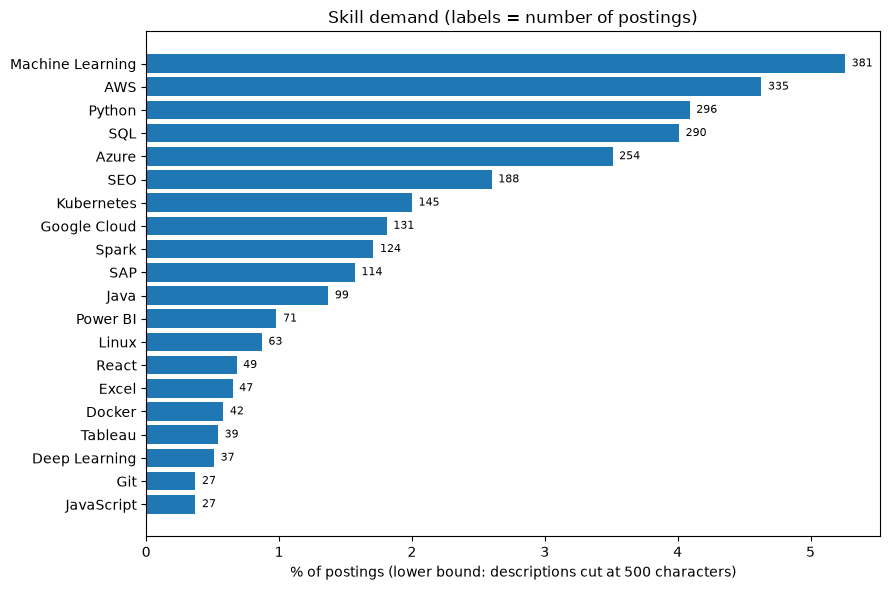

In [341]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(order[::-1], demand["pct_postings"][::-1], color="tab:blue")
for y, (pct, n) in enumerate(zip(demand["pct_postings"][::-1], demand["frequency"][::-1])):
    ax.text(pct + 0.05, y, str(n), va="center", fontsize=8)
ax.set_xlabel("% of postings (lower bound: descriptions cut at 500 characters)")
ax.set_title("Skill demand (labels = number of postings)")
fig.tight_layout()
fig.savefig(OUT / "01_skill_frequency.png", dpi=120)
plt.show()

### Skills by role

Share of each role's own postings that mention each skill.

In [342]:
# Share of each role's own postings that mention each skill.
by_role = M.groupby(df["role"]).sum()
role_n = df["role"].value_counts()
by_role_pct = (100 * by_role.div(role_n, axis=0))[order]
by_role_pct = by_role_pct.loc[by_role_pct.max(axis=1).sort_values(ascending=False).index]

(by_role.stack().rename("frequency").rename_axis(["role", "skill"]).reset_index()
 .assign(role_postings=lambda t: t["role"].map(role_n),
         pct_of_role_postings=lambda t: (100 * t["frequency"] / t["role_postings"]).round(2))
 .to_csv(OUT / "skill_demand_by_role.csv", index=False))

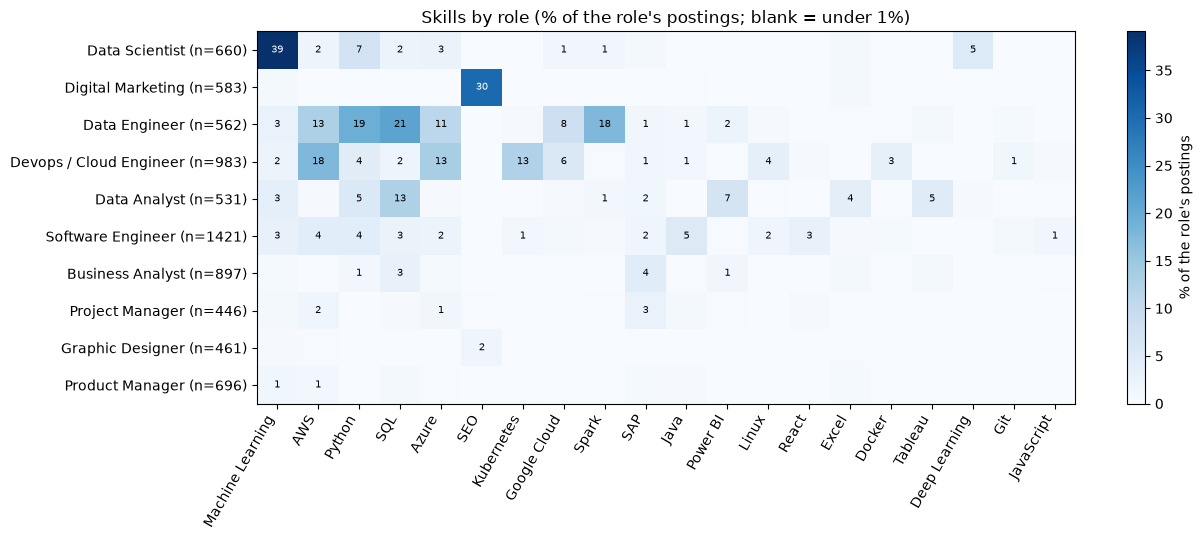

In [343]:
heatmap(by_role_pct.rename(index=lambda r: f"{r} (n={role_n[r]})"),
        "Skills by role (% of the role's postings; blank = under 1%)",
        "% of the role's postings", OUT / "02_role_skill_heatmap.png", "Blues", (13, 5.5))

In [344]:
top3 = {role: ", ".join(f"{s} ({by_role_pct.loc[role, s]:.0f}%)"
                        for s in by_role_pct.loc[role].nlargest(3).index)
        for role in by_role_pct.index}
display(pd.Series(top3, name="top 3 skills").to_frame())

,top 3 skills
Data Scientist,"Machine Learning (39%), Python (7%), Deep Lear..."
Digital Marketing,"SEO (30%), Machine Learning (1%), Excel (1%)"
Data Engineer,"SQL (21%), Python (19%), Spark (18%)"
Devops / Cloud Engineer,"AWS (18%), Azure (13%), Kubernetes (13%)"
Data Analyst,"SQL (13%), Power BI (7%), Python (5%)"
Software Engineer,"Java (5%), AWS (4%), Python (4%)"
Business Analyst,"SAP (4%), SQL (3%), Power BI (1%)"
Project Manager,"SAP (3%), AWS (2%), Azure (1%)"
Graphic Designer,"SEO (2%), Machine Learning (0%), AWS (0%)"
Product Manager,"Machine Learning (1%), AWS (1%), SQL (1%)"


## 4. Skill co-occurrence

Two skills co-occur when one posting mentions both.

- `together`: postings with both skills.
- `lift`: `together` divided by the count expected if the two skills were unrelated. Above 1 means they
  appear together more often than chance.
- `jaccard`: `together` divided by postings with either skill.

Pairs seen in fewer than 5 postings are not ranked, because their lift is noise.

In [345]:
Mi = M.astype(int)
C = Mi.T @ Mi                 # co-occurrence counts, diagonal = skill frequency
f = M.sum()
pairs = pd.DataFrame([
    {"skill_a": a, "skill_b": b, "together": int(C.loc[a, b]),
     "lift": round(C.loc[a, b] * N / (f[a] * f[b]), 2),
     "jaccard": round(C.loc[a, b] / (f[a] + f[b] - C.loc[a, b]), 3)}
    for i, a in enumerate(skills) for b in skills[i + 1:] if C.loc[a, b] > 0
]).sort_values(["together", "lift"], ascending=False).reset_index(drop=True)
pairs.to_csv(OUT / "cooccurrence_pairs.csv", index=False)

ranked = pairs[pairs["together"] >= 5]
print(f"{len(pairs)} of {len(skills) * (len(skills) - 1) // 2} pairs occur at least once; "
      f"{len(ranked)} occur in 5 or more postings")
display(ranked.head(15))

122 of 190 pairs occur at least once; 75 occur in 5 or more postings


,skill_a,skill_b,together,lift,jaccard
0,Python,SQL,133,11.22,0.294
1,AWS,Azure,87,7.40,0.173
2,AWS,Python,76,5.55,0.137
3,Python,Spark,75,14.79,0.217
4,SQL,Spark,69,13.89,0.200
5,AWS,Kubernetes,55,8.20,0.129
6,SQL,Azure,55,5.41,0.112
7,Python,Azure,55,5.30,0.111
8,AWS,Google Cloud,54,8.91,0.131
9,Python,Machine Learning,50,3.21,0.080


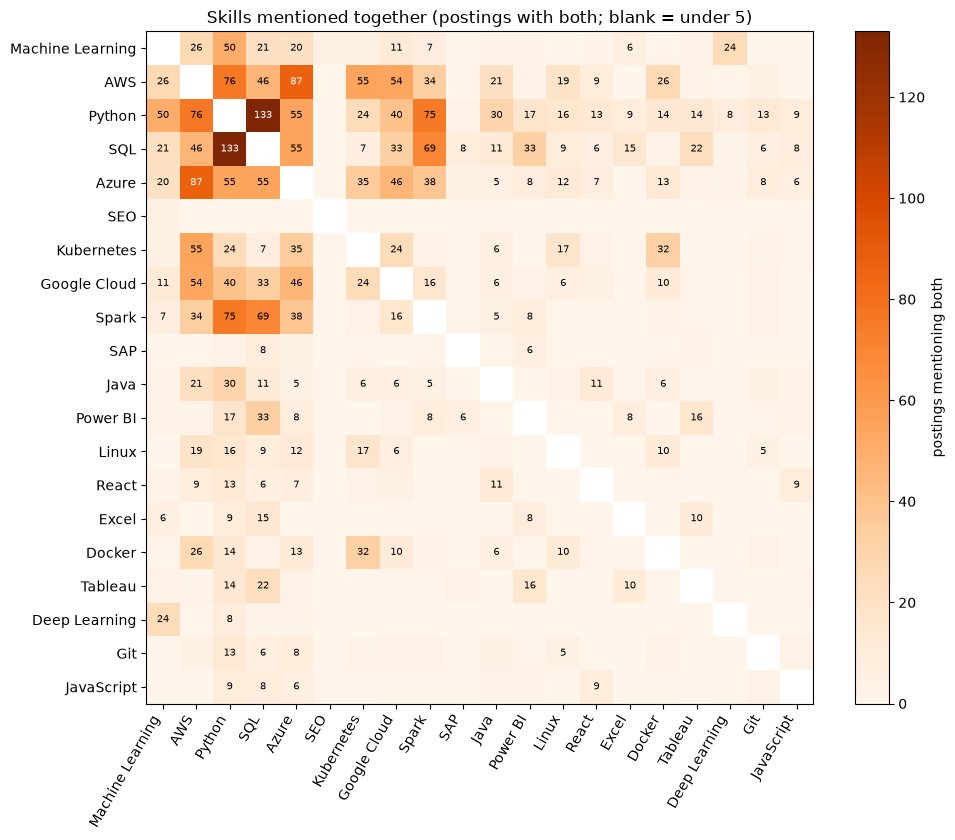

In [346]:
cooc = C.loc[order, order].astype(float).mask(np.eye(len(order), dtype=bool))  # blank the diagonal
heatmap(cooc, "Skills mentioned together (postings with both; blank = under 5)",
        "postings mentioning both", OUT / "03_cooccurrence_heatmap.png", "Oranges", (10, 8.5), min_label=5)

## 5. Term-document matrix and TF-IDF

The term-document matrix has one row per posting and one column per word, with word counts in the cells
(bag-of-words: word order is ignored). TF-IDF lowers the weight of words that appear in most postings.
Built on `description_clean` (lemmatised). The table lists, per role, the words with the largest
TF-IDF above the all-postings average.

In [347]:
texts_clean = df["description_clean"].fillna("")

counts = CountVectorizer(min_df=5).fit_transform(texts_clean)
print(f"term-document matrix: {counts.shape[0]:,} postings x {counts.shape[1]:,} words, "
      f"{100 * (1 - counts.nnz / np.prod(counts.shape)):.1f}% of cells are zero")

term-document matrix: 7,240 postings x 3,869 words, 99.0% of cells are zero


### Distinctive words per role

In [348]:
tfidf = TfidfVectorizer(min_df=5)
T = tfidf.fit_transform(texts_clean)
words = np.array(tfidf.get_feature_names_out())
average = np.asarray(T.mean(axis=0)).ravel()

rows = []
for role, idx in df.groupby("role").indices.items():
    lift = np.asarray(T[idx].mean(axis=0)).ravel() - average
    rows += [{"role": role, "rank": r, "term": words[j], "tfidf_above_average": round(float(lift[j]), 4)}
             for r, j in enumerate(np.argsort(lift)[::-1][:8], 1)]
distinctive = pd.DataFrame(rows)
distinctive.to_csv(OUT / "tfidf_distinctive_terms_by_role.csv", index=False)
display(distinctive.groupby("role")["term"].apply(", ".join).to_frame("most distinctive words"))

,most distinctive words
role,
Business Analyst,"business, analyst, requirement, process, funct..."
Data Analyst,"datum, analyst, analytic, data, insight, repor..."
Data Engineer,"data, datum, pipeline, etl, engineer, analytic..."
Data Scientist,"scientist, machine, model, learning, ai, ml, s..."
Devops / Cloud Engineer,"cloud, infrastructure, devop, reliability, pla..."
Digital Marketing,"marketing, digital, campaign, seo, performance..."
Graphic Designer,"graphic, creative, designer, visual, design, b..."
Product Manager,"product, owner, manager, roadmap, customer, vi..."
Project Manager,"project, manager, delivery, end, execution, te..."


## 6. Clustering

Only the raw description is used as input. `role` comes from the job title, so it is never a model input.
It is used to check the clusters and, because it is an outside label, to choose between settings. That
makes the scores a little optimistic, which is why section 6.9 repeats the test on postings the model did
not see.

Every setup is scored the same way, so they can be compared:

- **NMI** and **ARI**: agreement with role (0 for random labels, 1 for identical). Mean of 5 seeds.
- **Silhouette**: how well separated the clusters are, with cosine distance in the TF-IDF space, the same
  space for every setup that uses the baseline vocabulary.
- **Stability**: mean ARI between the 5 runs. 1 means the same clusters every time.
- **Smallest cluster**: the minimum over the 5 runs. A cluster under 100 postings is not a usable group.

**Experiments**, each changing one thing:

| Step | Change | Kept if |
|---|---|---|
| Baseline | TF-IDF, K = 10 | |
| A | remove boilerplate phrases | NMI rises by more than the seed noise, and stability does not fall by more than 0.05 |
| B | add word pairs (bigrams) | same rule |
| C | SVD before K-Means, 50 to 300 dimensions, plain or scaled to unit length; the setup with the best NMI | same rule against the baseline |
| D | K from 4 to 20 on the kept representation | smallest cluster 100 or more in every run and stability at least 0.7; then the best NMI |

Seed noise is the larger standard deviation of NMI over the 5 seeds of the two setups being compared.

### 6.1 Text cleaning and helper functions

Decode HTML, remove URLs, lower-case, drop English stop words, no stemming. The tokenizer keeps `C++`,
`C#`, `Node.js` and `CI/CD` whole, which the default tokenizer splits.

In [349]:
TOKEN_PATTERN = r"(?u)\b[a-zA-Z][a-zA-Z0-9]*(?:[+#./][a-zA-Z0-9]+)*\b"
STOP_WORDS = sorted(ENGLISH_STOP_WORDS)
URL = re.compile(r"https?://\S+|www\.\S+")
BOILERPLATE = ["job description", "about the role", "about us", "about the company", "who we are",
               "we are looking for", "we are seeking", "the ideal candidate", "ideal candidate will",
               "ideal candidate should", "to join our", "mygwork", "lgbtq", "inclusive employer",
               "equal opportunity employer"]


def prepare(text, drop_boilerplate=False):
    text = URL.sub(" ", html.unescape(str(text))).lower()
    if drop_boilerplate:
        for phrase in BOILERPLATE:
            text = text.replace(phrase, " ")
    return text


def fit_tfidf(texts, ngram_range=(1, 1), min_df=5, max_df=0.6):
    vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words=STOP_WORDS, lowercase=False,
                          ngram_range=ngram_range, min_df=min_df, max_df=max_df, sublinear_tf=True)
    return vec, vec.fit_transform(texts)

Helpers that cluster, score and record each experiment. `verdict` applies the keep rule.

In [350]:
SEEDS = [SEED, 0, 1, 2, 3]
STABILITY_TOLERANCE = 0.05     # stability is a mean over only 5 seeds, so small differences are noise
experiments = []


def cluster(X, k):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    return model, model.labels_


def evaluate(step, setup, X, k, reference=None):
    """Cluster X into k groups with each seed, score the runs, and record the row."""
    runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X) for s in SEEDS]
    nmis = [normalized_mutual_info_score(df["role"], r) for r in runs]
    row = {"step": step, "setup": setup, "k": k,
           "nmi": np.mean(nmis), "nmi_sd": np.std(nmis),
           "ari": np.mean([adjusted_rand_score(df["role"], r) for r in runs]),
           "silhouette": silhouette_score(X if reference is None else reference, runs[0], metric="cosine"),
           "stability": np.mean([adjusted_rand_score(a, b) for i, a in enumerate(runs) for b in runs[i + 1:]]),
           "smallest_cluster": min(int(np.bincount(r).min()) for r in runs)}
    experiments.append(row)
    return row


def verdict(row, reference):
    """Keep rule: NMI gain larger than the seed noise, and stability not lower by more than the tolerance."""
    gain = row["nmi"] - reference["nmi"]
    noise = max(row["nmi_sd"], reference["nmi_sd"])
    keep = gain > noise and row["stability"] >= reference["stability"] - STABILITY_TOLERANCE
    print(f"NMI {gain:+.3f} (seed noise {noise:.3f}), stability {row['stability'] - reference['stability']:+.3f}, "
          f"silhouette {row['silhouette'] - reference['silhouette']:+.4f} -> {'kept' if keep else 'not kept'}")
    return keep

### 6.2 Baseline: TF-IDF, K = 10

K = 10 is a starting point (the data has 10 roles), not the final choice. Experiment D tests K.

In [351]:
text_plain = df["description_raw"].map(prepare)
vec, X_tfidf = fit_tfidf(text_plain)
print(f"TF-IDF matrix: {X_tfidf.shape[0]:,} postings x {X_tfidf.shape[1]:,} words")

baseline_row = evaluate("baseline", "TF-IDF, K=10", X_tfidf, 10)
display(pd.DataFrame([baseline_row]).round(4))

TF-IDF matrix: 7,240 postings x 4,715 words


,step,setup,k,nmi,nmi_sd,ari,silhouette,stability,smallest_cluster
0,baseline,"TF-IDF, K=10",10,0.3494,0.0134,0.173,0.0224,0.6061,45


### 6.3 Experiment A: remove boilerplate phrases

Phrases such as "job description" and the myGwork badge text appear in many postings and say nothing
about the job. Only the cleaning changes.

In [352]:
_, X_a = fit_tfidf(df["description_raw"].map(lambda t: prepare(t, drop_boilerplate=True)))
row_a = evaluate("A", "boilerplate removed", X_a, 10)
verdict(row_a, baseline_row)

NMI -0.003 (seed noise 0.026), stability -0.045, silhouette -0.0015 -> not kept


np.False_

### 6.4 Experiment B: add word pairs (bigrams)

Tests whether pairs such as "data pipeline" add information. Only `ngram_range` changes, from (1, 1) to
(1, 2).

In [ ]:
vec_b, X_b = fit_tfidf(text_plain, ngram_range=(1, 2))
print(f"vocabulary: {len(vec_b.vocabulary_):,} words ({len(vec_b.vocabulary_) / X_tfidf.shape[1]:.1f}x the baseline)")
row_b = evaluate("B", "bigrams", X_b, 10)
verdict(row_b, baseline_row)szx

vocabulary: 16,173 words (3.4x the baseline)
NMI -0.004 (seed noise 0.021), stability -0.005, silhouette +0.0017 -> not kept


np.False_

### 6.5 Experiment C: reduce dimensions with SVD

TF-IDF is large and sparse, so K-Means works poorly on it. Truncated SVD keeps the strongest directions in
fewer, dense columns. This is the same idea as latent semantic indexing.

K-Means uses Euclidean distance, while TF-IDF similarity is cosine similarity. Scaling each posting's SVD
vector to length 1 makes the two agree, and it is the usual step in latent semantic analysis. So each size
is tried plain and scaled. Setups whose NMI is within one seed noise of the best count as tied, and the most
stable of them is compared with the baseline. Choosing among 14 setups is optimistic, which is why section 6.9
tests the result on held-out postings.

The first version of this rule required stability not to fall at all and took the single best NMI. It
rejected the best setup because its stability was 0.006 lower, which is below the noise of a 5-seed
average, so the rule was relaxed to the tolerance above. The NMI ranking itself did not change.

In [354]:
for n in (50, 75, 100, 125, 150, 200, 300):
    X_n = TruncatedSVD(n, random_state=SEED).fit_transform(X_tfidf)
    evaluate("C", f"SVD {n}", X_n, 10, reference=X_tfidf)
    evaluate("C", f"SVD {n}, unit length", Normalizer().fit_transform(X_n), 10, reference=X_tfidf)

sweep_c = pd.DataFrame(experiments).query("step == 'C'")
sweep_c = sweep_c.assign(scaled=sweep_c["setup"].str.contains("unit length"))
display(sweep_c.drop(columns=["step", "k", "scaled"]).round(4))

,setup,nmi,nmi_sd,ari,silhouette,stability,smallest_cluster
3,SVD 50,0.3451,0.0322,0.1571,0.0194,0.6180,22
4,"SVD 50, unit length",0.4051,0.0117,0.2598,0.0251,0.7841,336
5,SVD 75,0.3508,0.0137,0.1610,0.0180,0.5660,36
6,"SVD 75, unit length",0.3975,0.0199,0.2528,0.0251,0.6484,331
7,SVD 100,0.3468,0.0365,0.1544,0.0185,0.6437,28
8,"SVD 100, unit length",0.4106,0.0212,0.2460,0.0242,0.6117,324
9,SVD 125,0.3421,0.0196,0.1541,0.0182,0.5746,22
10,"SVD 125, unit length",0.4101,0.0144,0.2369,0.0261,0.6079,155
11,SVD 150,0.3269,0.0338,0.1548,0.0179,0.6213,14
12,"SVD 150, unit length",0.4167,0.0269,0.2357,0.0240,0.5998,155


In [355]:
print("best plain SVD against the baseline:")
verdict(sweep_c[~sweep_c["scaled"]].sort_values("nmi").iloc[-1], baseline_row)
print("best unit-length SVD against the baseline:")
scaled = sweep_c[sweep_c["scaled"]]
best_nmi = scaled.sort_values("nmi").iloc[-1]
# NMI differences below the seed noise are not real, so among the setups within one noise of the best
# the most stable one is taken.
near_best = scaled[scaled["nmi"] >= best_nmi["nmi"] - best_nmi["nmi_sd"]]
best_c = near_best.sort_values("stability").iloc[-1]
print(f"{len(near_best)} scaled setups are within one seed noise of the best NMI; the most stable is {best_c['setup']}")
assert verdict(best_c, baseline_row), "no SVD setup beats the baseline: revisit the pipeline"

SVD_DIMS, SCALE_TO_UNIT = int(best_c["setup"].split()[1].rstrip(",")), True
svd = TruncatedSVD(SVD_DIMS, random_state=SEED)
X_svd = svd.fit_transform(X_tfidf)
Z = Normalizer().fit_transform(X_svd)
print(f"kept: SVD {SVD_DIMS}, scaled to unit length")

best plain SVD against the baseline:
NMI +0.001 (seed noise 0.014), stability -0.040, silhouette -0.0044 -> not kept
best unit-length SVD against the baseline:
6 scaled setups are within one seed noise of the best NMI; the most stable is SVD 50, unit length
NMI +0.056 (seed noise 0.013), stability +0.178, silhouette +0.0027 -> kept
kept: SVD 50, scaled to unit length


### 6.6 Experiment D: number of clusters

Silhouette keeps rising as K grows, because small clusters are tight. The first version of this rule chose
the best silhouette among the eligible K and returned K = 20, the edge of the grid, for 10 roles. So
silhouette cannot choose K here, and the rule was changed.

A K is eligible if the smallest cluster has 100 or more postings in every run (a smaller cluster is not a
usable group) and the runs agree with each other (stability at least 0.7). Among the eligible K, the one
with the best NMI is taken, because the aim is to recover occupations. The role label therefore helps to
choose K, which is why section 6.9 tests the result on held-out postings.

In [356]:
for k in (4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 20):
    evaluate("D", f"K={k}", Z, k, reference=X_tfidf)

sweep_e = pd.DataFrame(experiments).query("step == 'D'")
display(sweep_e.drop(columns=["step", "setup"]).round(4))

MIN_STABILITY = 0.7
eligible = sweep_e[(sweep_e["smallest_cluster"] >= 100) & (sweep_e["stability"] >= MIN_STABILITY)]
K = int(eligible.loc[eligible["nmi"].idxmax(), "k"])
print(f"eligible K: {eligible['k'].tolist()} -> K = {K}")

,k,nmi,nmi_sd,ari,silhouette,stability,smallest_cluster
17,4,0.2917,0.0001,0.1461,0.0216,0.9964,866
18,5,0.3524,0.0010,0.1861,0.0218,0.9946,861
19,6,0.3475,0.0192,0.1956,0.0222,0.6910,363
20,7,0.3603,0.0042,0.2022,0.0226,0.8159,360
21,8,0.3690,0.0216,0.2108,0.0233,0.6908,360
22,9,0.3792,0.0180,0.2364,0.0244,0.7214,360
23,10,0.4051,0.0117,0.2598,0.0251,0.7841,336
24,11,0.3969,0.0166,0.2574,0.0250,0.7450,156
25,12,0.4180,0.0096,0.2771,0.0290,0.8210,156
26,14,0.4046,0.0153,0.2592,0.0305,0.6989,139


eligible K: [4, 5, 7, 9, 10, 11, 12, 16, 20] -> K = 12


### 6.7 All experiments

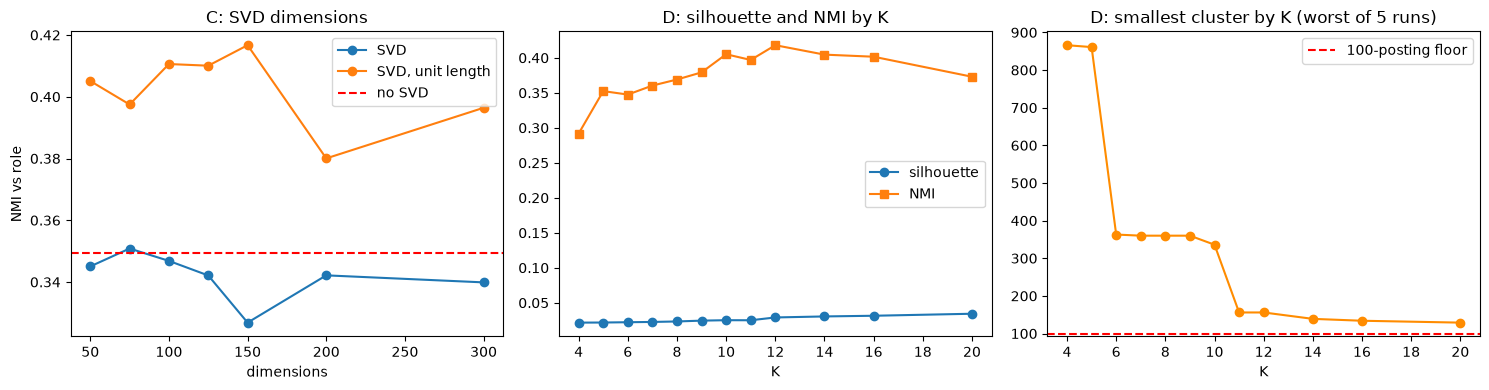

In [357]:
results = pd.DataFrame(experiments)
results.to_csv(OUT / "cluster_experiments.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for scaled_flag, label in ((False, "SVD"), (True, "SVD, unit length")):
    part = sweep_c[sweep_c["scaled"] == scaled_flag]
    axes[0].plot([int(t.split()[1].rstrip(",")) for t in part["setup"]], part["nmi"], marker="o", label=label)
axes[0].axhline(baseline_row["nmi"], color="red", linestyle="--", label="no SVD")
axes[0].set(title="C: SVD dimensions", xlabel="dimensions", ylabel="NMI vs role")
axes[0].legend()
axes[1].plot(sweep_e["k"], sweep_e["silhouette"], marker="o", label="silhouette")
axes[1].plot(sweep_e["k"], sweep_e["nmi"], marker="s", label="NMI")
axes[1].set(title="D: silhouette and NMI by K", xlabel="K")
axes[1].legend()
axes[2].plot(sweep_e["k"], sweep_e["smallest_cluster"], marker="o", color="darkorange")
axes[2].axhline(100, color="red", linestyle="--", label="100-posting floor")
axes[2].set(title="D: smallest cluster by K (worst of 5 runs)", xlabel="K")
axes[2].legend()
fig.tight_layout()
fig.savefig(OUT / "06_svd_k_sweep.png", dpi=120)
plt.show()

### 6.8 Final model and cluster contents

In [358]:
km, labels = cluster(Z, K)
df["cluster"] = labels
final_row = sweep_e[sweep_e["k"] == K].iloc[0]

final = {"silhouette": silhouette_score(X_tfidf, labels, metric="cosine"),
         "nmi": normalized_mutual_info_score(df["role"], labels),
         "ari": adjusted_rand_score(df["role"], labels)}
baseline = {"silhouette": baseline_row["silhouette"], "nmi": baseline_row["nmi"], "ari": baseline_row["ari"]}
display(pd.DataFrame({"baseline (TF-IDF, K=10)": baseline, f"final (K={K}, seed {SEED})": final}).round(4))
print(f"final setup over 5 seeds: NMI {final_row['nmi']:.3f} +/- {final_row['nmi_sd']:.3f}, "
      f"stability {final_row['stability']:.2f}, smallest cluster {final_row['smallest_cluster']}")

,"baseline (TF-IDF, K=10)","final (K=12, seed 42)"
silhouette,0.0224,0.0290
nmi,0.3494,0.4093
ari,0.1730,0.2691


final setup over 5 seeds: NMI 0.418 +/- 0.010, stability 0.82, smallest cluster 156


In [359]:
# A cluster is described by the words with the highest mean TF-IDF among its postings.
words = np.array(vec.get_feature_names_out())
cluster_words = [words[np.argsort(-np.asarray(X_tfidf[labels == c].mean(axis=0)).ravel())[:12]] for c in range(K)]
summary = pd.DataFrame([{
    "cluster": c,
    "size": int((labels == c).sum()),
    "top_words": ", ".join(cluster_words[c]),
    "top_roles": "; ".join(f"{r} ({100 * p:.0f}%)"
                           for r, p in df.loc[labels == c, "role"].value_counts(normalize=True).head(3).items()),
} for c in range(K)])
with pd.option_context("display.max_colwidth", 110):
    display(summary)

,cluster,size,top_words,top_roles
0,0,448,"product, manager, role, owner, business, roadmap, products, strategy, management, team, customer, experience",Product Manager (76%); Business Analyst (11%); Software Engineer (4%)
1,1,507,"marketing, digital, campaigns, seo, performance, media, content, social, ads, google, strategies, paid",Digital Marketing (93%); Graphic Designer (4%); Business Analyst (1%)
2,2,810,"company, global, technology, services, india, solutions, leading, financial, s, world, digital, clients",Software Engineer (17%); Product Manager (15%); Business Analyst (15%)
3,3,728,"software, engineer, applications, development, role, design, experience, application, skills, systems, sol...",Software Engineer (85%); Devops / Cloud Engineer (7%); Business Analyst (3%)
4,4,527,"business, analyst, requirements, functional, processes, support, role, teams, stakeholders, analysis, job,...",Business Analyst (76%); Data Analyst (9%); Software Engineer (5%)
5,5,360,"graphic, designer, creative, visual, design, brand, media, social, marketing, digital, create, graphics",Graphic Designer (96%); Digital Marketing (3%); Business Analyst (0%)
6,6,636,"ai, platform, data, scale, agentic, s, enterprise, powered, intelligence, building, engineering, real",Software Engineer (26%); Data Scientist (23%); Devops / Cloud Engineer (17%)
7,7,1144,"people, world, s, work, customers, technology, make, help, career, team, global, join",Software Engineer (25%); Data Scientist (17%); Devops / Cloud Engineer (14%)
8,8,156,"lgbtq, mygwork, recruiter, employer, inclusive, contact, member, community, directly, largest, global, pla...",Software Engineer (54%); Business Analyst (22%); Data Analyst (6%)
9,9,564,"cloud, infrastructure, devops, engineer, reliability, aws, ci/cd, platform, automation, role, azure, exper...",Devops / Cloud Engineer (90%); Software Engineer (7%); Data Engineer (2%)


In [360]:
summary.to_csv(OUT / "cluster_summary.csv", index=False)
df[["job_id", "role", "cluster"]].to_csv(OUT / "cluster_assignments.csv", index=False)

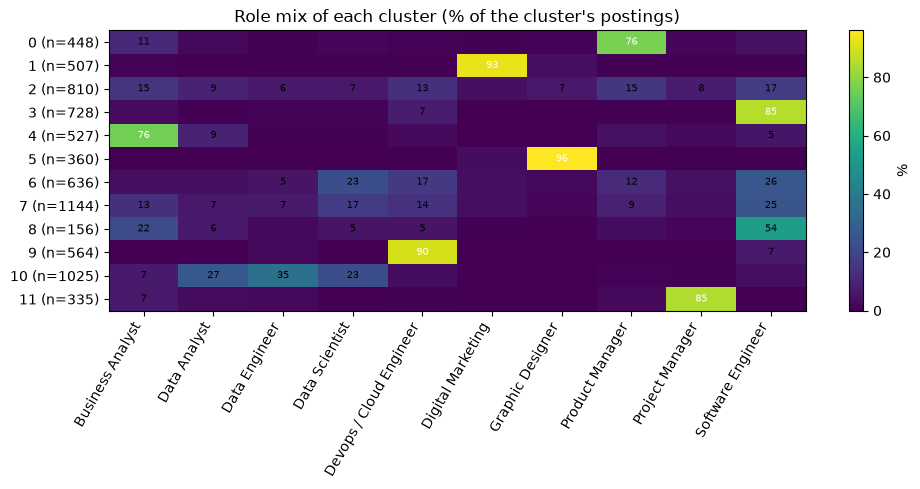

In [361]:
share = pd.crosstab(df["cluster"], df["role"], normalize="index") * 100
heatmap(share.rename(index=lambda c: f"{c} (n={int((labels == c).sum())})"),
        "Role mix of each cluster (% of the cluster's postings)", "%",
        OUT / "07_cluster_role_heatmap.png", "viridis", (10, 5), min_label=5)

### 6.9 Held-out test

Everything above was fitted on all postings and used role to choose settings. To test the result on
postings the model has not seen, the vectorizer, SVD and K-Means are fitted on a random 80% and the other
20% is assigned to the nearest cluster. If the scores hold on the held-out 20%, the clusters are not an
artefact of the fitting data.

In [362]:
def project(X, svd_model):
    """TF-IDF matrix -> the representation that K-Means is fitted on."""
    Z_part = svd_model.transform(X)
    return Normalizer().fit_transform(Z_part) if SCALE_TO_UNIT else Z_part


perm = np.random.RandomState(SEED).permutation(N)
train_idx, test_idx = perm[: int(0.8 * N)], perm[int(0.8 * N):]

vec_h, X_train = fit_tfidf(text_plain.iloc[train_idx])
X_test = vec_h.transform(text_plain.iloc[test_idx])
svd_h = TruncatedSVD(SVD_DIMS, random_state=SEED).fit(X_train)
km_h = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(project(X_train, svd_h))

held_out = []
for part, X_part, rows in (("fitted on (80%)", X_train, train_idx), ("held out (20%)", X_test, test_idx)):
    labels_h = km_h.predict(project(X_part, svd_h))
    held_out.append({"part": part, "postings": len(rows),
                     "silhouette": silhouette_score(X_part, labels_h, metric="cosine"),
                     "nmi": normalized_mutual_info_score(df["role"].iloc[rows], labels_h),
                     "ari": adjusted_rand_score(df["role"].iloc[rows], labels_h)})
held_out = pd.DataFrame(held_out)
held_out.to_csv(OUT / "cluster_held_out.csv", index=False)
display(held_out.round(4))

,part,postings,silhouette,nmi,ari
0,fitted on (80%),5792,0.0265,0.4210,0.2863
1,held out (20%),1448,0.0271,0.4333,0.2878


### 6.10 Vectorizer settings

`min_df` (a word must appear in at least this many postings) and `max_df` (a word in more than this share
of postings is dropped) were set by judgement. This grid checks whether the result depends on them. Every
cell uses the final pipeline (SVD, unit length if kept, K-Means with the final K).

In [363]:
grid = []
for min_df in (3, 5, 10):
    for max_df in (0.5, 0.6, 0.8):
        _, X_g = fit_tfidf(text_plain, min_df=min_df, max_df=max_df)
        Z_g = project(X_g, TruncatedSVD(SVD_DIMS, random_state=SEED).fit(X_g))
        labels_g = cluster(Z_g, K)[1]
        grid.append({"min_df": min_df, "max_df": max_df, "words": X_g.shape[1],
                     "silhouette": silhouette_score(X_g, labels_g, metric="cosine"),
                     "nmi": normalized_mutual_info_score(df["role"], labels_g),
                     "ari": adjusted_rand_score(df["role"], labels_g),
                     "smallest_cluster": int(np.bincount(labels_g).min())})
grid = pd.DataFrame(grid)
grid.to_csv(OUT / "cluster_vectorizer_grid.csv", index=False)
display(grid.round(4))
print(f"the most common word is in {(X_tfidf > 0).mean(axis=0).max():.0%} of postings, so max_df (0.5 and above) removes nothing")
print(f"NMI ranges from {grid['nmi'].min():.3f} to {grid['nmi'].max():.3f}; "
      f"the chosen setting (min_df=5, max_df=0.6) gives {grid.query('min_df == 5 and max_df == 0.6')['nmi'].iloc[0]:.3f}")

,min_df,max_df,words,silhouette,nmi,ari,smallest_cluster
0,3,0.5,6593,0.0279,0.4104,0.2757,157
1,3,0.6,6593,0.0279,0.4104,0.2757,157
2,3,0.8,6593,0.0279,0.4104,0.2757,157
3,5,0.5,4715,0.0290,0.4093,0.2691,156
4,5,0.6,4715,0.0290,0.4093,0.2691,156
5,5,0.8,4715,0.0290,0.4093,0.2691,156
6,10,0.5,3119,0.0320,0.3887,0.2572,157
7,10,0.6,3119,0.0320,0.3887,0.2572,157
8,10,0.8,3119,0.0320,0.3887,0.2572,157


the most common word is in 36% of postings, so max_df (0.5 and above) removes nothing
NMI ranges from 0.389 to 0.410; the chosen setting (min_df=5, max_df=0.6) gives 0.409


### 6.11 Alternatives on equal terms

Every candidate is scored as in section 6 (NMI, ARI, cosine silhouette in the TF-IDF space, smallest
cluster), with stability over 10 seeds. Ward clustering is deterministic, so its stability is 1 by
construction.

In [364]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

methods = {
    f"K-Means on TF-IDF (K={K})": lambda seed: KMeans(K, n_init=10, random_state=seed).fit_predict(X_tfidf),
    f"K-Means on SVD {SVD_DIMS}, not scaled (K={K})": lambda seed: KMeans(K, n_init=10, random_state=seed).fit_predict(X_svd),
    f"K-Means on final representation (K={K}), chosen": lambda seed: KMeans(K, n_init=10, random_state=seed).fit_predict(Z),
    "K-Means on final representation (K=10, one per role)": lambda seed: KMeans(10, n_init=10, random_state=seed).fit_predict(Z),
    f"Ward hierarchical on final representation (K={K})": lambda seed: AgglomerativeClustering(K, linkage="ward").fit_predict(Z),
    f"Gaussian mixture on final representation (K={K})": lambda seed: GaussianMixture(K, covariance_type="diag", random_state=seed).fit_predict(Z),
}

compared = []
for name, run in methods.items():
    runs = [run(seed) for seed in range(10)]
    reported = run(SEED)
    compared.append({"method": name, "nmi": normalized_mutual_info_score(df["role"], reported),
                     "ari": adjusted_rand_score(df["role"], reported),
                     "silhouette": silhouette_score(X_tfidf, reported, metric="cosine"),
                     "smallest_cluster": int(np.bincount(reported).min()),
                     "stability": np.mean([adjusted_rand_score(a, b) for i, a in enumerate(runs) for b in runs[i + 1:]])})
compared = pd.DataFrame(compared)
compared.to_csv(OUT / "cluster_alternatives.csv", index=False)
display(compared.round(3))

,method,nmi,ari,silhouette,smallest_cluster,stability
0,K-Means on TF-IDF (K=12),0.375,0.199,0.025,130,0.538
1,"K-Means on SVD 50, not scaled (K=12)",0.338,0.147,0.021,29,0.582
2,"K-Means on final representation (K=12), chosen",0.409,0.269,0.029,156,0.766
3,"K-Means on final representation (K=10, one per...",0.401,0.260,0.025,344,0.759
4,Ward hierarchical on final representation (K=12),0.344,0.202,0.020,300,1.000
5,Gaussian mixture on final representation (K=12),0.373,0.216,0.020,268,0.565


## 7. Topic model (LDA)

The skill list only finds skills we already named. Latent Dirichlet Allocation finds groups of words that
occur together without being told any skill.

- Fitted on distinct descriptions, so a text posted many times does not dominate a topic.
- Words in more than 50% of postings or in fewer than 5 are dropped.
- Number of topics: fit K = 4, 6, 8, 10 on 80% of the postings and take the K with the lowest perplexity on
  the other 20% (split fixed by the seed). NMI against role is shown beside it.

In [365]:
pool = df[~is_copy.values].reset_index(drop=True)
cv = CountVectorizer(min_df=5, max_df=0.5)
X_lda = cv.fit_transform(pool["description_clean"].fillna(""))
lda_words = np.array(cv.get_feature_names_out())
order_idx = np.random.RandomState(SEED).permutation(X_lda.shape[0])
train, test = order_idx[:int(0.8 * len(order_idx))], order_idx[int(0.8 * len(order_idx)):]

### Choose the number of topics

In [366]:
def fit_lda(k, rows):
    return LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=25,
                                     random_state=SEED).fit(X_lda[rows])


sweep = []
for k in (4, 6, 8, 10):
    m = fit_lda(k, train)
    sweep.append({"K": k, "held_out_perplexity": round(float(m.perplexity(X_lda[test])), 1),
                  "NMI_vs_role": round(normalized_mutual_info_score(pool["role"], m.transform(X_lda).argmax(axis=1)), 3)})
sweep = pd.DataFrame(sweep)
sweep.to_csv(OUT / "lda_k_selection.csv", index=False)
K_LDA = int(sweep.loc[sweep["held_out_perplexity"].idxmin(), "K"])
display(sweep)
print(f"K = {K_LDA} (lowest held-out perplexity)")

,K,held_out_perplexity,NMI_vs_role
0,4,1022.7,0.271
1,6,1078.7,0.345
2,8,1139.6,0.288
3,10,1175.5,0.294


K = 4 (lowest held-out perplexity)


In [367]:
lda = fit_lda(K_LDA, np.arange(X_lda.shape[0]))
weights = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

# Names are our reading of each topic's top words, not model output.
TOPIC_NAMES = {0: "Employer & company description", 1: "Marketing, design & project delivery",
               2: "Data, analytics & business/product", 3: "Engineering, cloud & software"}


def name(t):
    return TOPIC_NAMES.get(t, f"Topic {t}") if K_LDA == 4 else f"Topic {t}"

topic_words = pd.DataFrame([
    {"topic": t, "name": name(t), "rank": r, "term": lda_words[j], "weight": round(float(weights[t, j]), 4)}
    for t in range(K_LDA) for r, j in enumerate(np.argsort(weights[t])[::-1][:10], 1)])
topic_words.to_csv(OUT / "lda_topic_words.csv", index=False)
display(topic_words.groupby(["topic", "name"])["term"].apply(", ".join).to_frame("top 10 words"))

,,top 10 words
topic,name,
0,Employer & company description,"company, technology, global, team, work, custo..."
1,"Marketing, design & project delivery","marketing, digital, project, role, design, exp..."
2,"Data, analytics & business/product","datum, business, data, role, product, team, ex..."
3,"Engineering, cloud & software","engineer, cloud, software, role, platform, app..."


### Topics by role

In [368]:
topic_of = lda.transform(cv.transform(df["description_clean"].fillna(""))).argmax(axis=1)
topic_by_role = (pd.crosstab(df["role"], pd.Series(topic_of, name="topic"), normalize="index") * 100).round(1)
topic_by_role.columns = [f"{t}: {name(t)}" for t in topic_by_role.columns]
topic_by_role.to_csv(OUT / "lda_topic_by_role.csv")

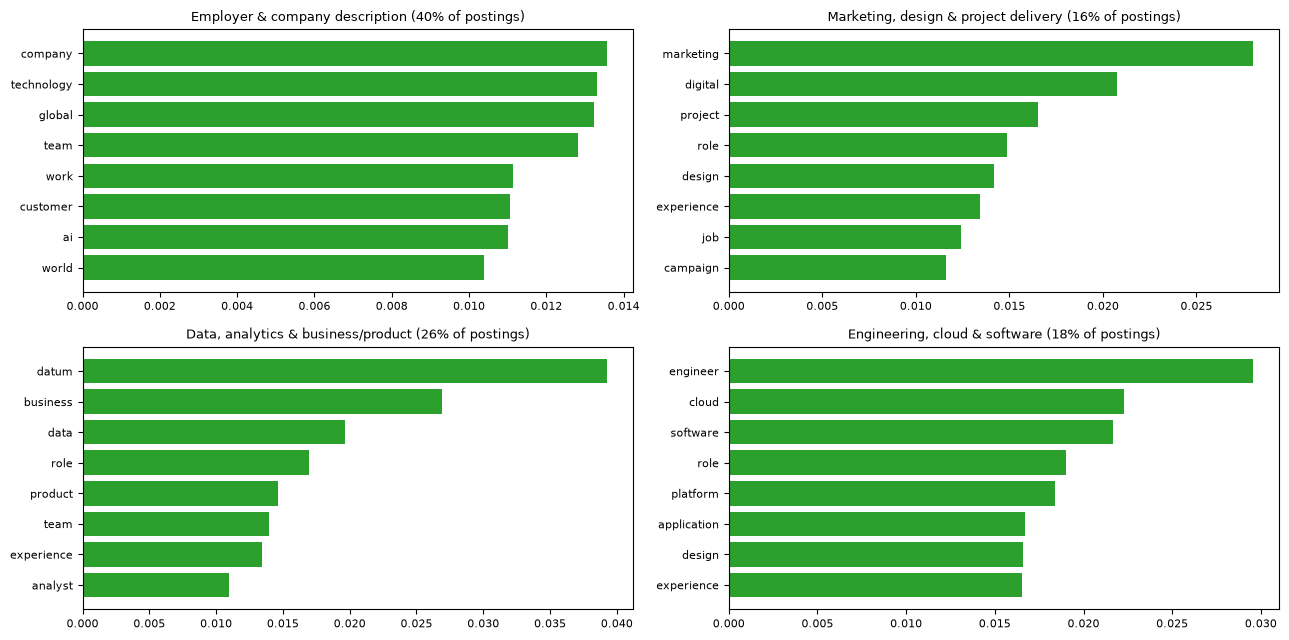

,0: Employer & company description,"1: Marketing, design & project delivery","2: Data, analytics & business/product","3: Engineering, cloud & software"
role,,,,
Business Analyst,40.1,1.4,56.4,2.0
Data Analyst,36.0,3.8,59.1,1.1
Data Engineer,32.2,1.2,52.3,14.2
Data Scientist,51.7,1.4,45.6,1.4
Devops / Cloud Engineer,35.8,0.6,3.5,60.1
Digital Marketing,18.5,81.1,0.2,0.2
Graphic Designer,19.7,79.8,0.0,0.4
Product Manager,55.6,6.5,34.1,3.9
Project Manager,32.7,38.3,25.3,3.6


In [369]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), squeeze=False)
for t, ax in enumerate(axes.ravel()[:K_LDA]):
    top = np.argsort(weights[t])[::-1][:8][::-1]
    ax.barh(lda_words[top], weights[t][top], color="tab:green")
    ax.set_title(f"{name(t)} ({100 * (topic_of == t).mean():.0f}% of postings)", fontsize=9)
    ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(OUT / "04_lda_topics.png", dpi=120)
plt.show()
display(topic_by_role)

### NMF as an alternative to LDA

Non-negative matrix factorisation (NMF) on TF-IDF is the usual alternative to LDA. Both models are fitted on
the same distinct descriptions and scored by how well their dominant topic matches role (NMI).

In [370]:
from sklearn.decomposition import NMF

tfidf_pool = TfidfVectorizer(min_df=5, max_df=0.5)
X_nmf = tfidf_pool.fit_transform(pool["description_clean"].fillna(""))
nmf_words = np.array(tfidf_pool.get_feature_names_out())

topic_compare = []
for k in (4, 6):
    nmf_k = NMF(n_components=k, init="nndsvda", max_iter=400, random_state=SEED).fit(X_nmf)
    lda_k = fit_lda(k, np.arange(X_lda.shape[0]))
    topic_compare.append({"topics": k,
                          "LDA_nmi": normalized_mutual_info_score(pool["role"], lda_k.transform(X_lda).argmax(axis=1)),
                          "NMF_nmi": normalized_mutual_info_score(pool["role"], nmf_k.transform(X_nmf).argmax(axis=1))})
    if k == K_LDA:
        nmf_final = nmf_k
topic_compare = pd.DataFrame(topic_compare)
topic_compare.to_csv(OUT / "topic_models_compared.csv", index=False)
display(topic_compare.round(3))
print(f"NMF topics (K={K_LDA}), top 8 words:")
for t, comp in enumerate(nmf_final.components_):
    print(f"  {t}: " + ", ".join(nmf_words[np.argsort(comp)[::-1][:8]]))

,topics,LDA_nmi,NMF_nmi
0,4,0.272,0.269
1,6,0.346,0.365


NMF topics (K=4), top 8 words:
  0: datum, data, cloud, engineer, infrastructure, pipeline, platform, experience
  1: marketing, digital, campaign, creative, medium, social, graphic, brand
  2: product, ai, business, technology, team, global, customer, company
  3: project, business, requirement, year, role, skill, application, experience


## 8. Skills inside each cluster

The clusters were built from text alone, without the skill list. If they also differ in the skills they
mention, the two methods support each other.

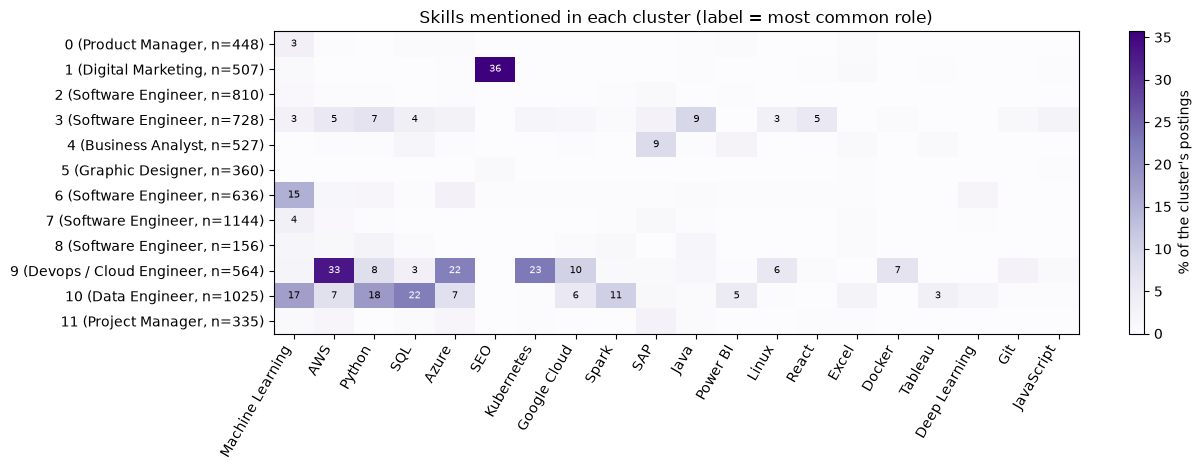

,% mentioning any skill
cluster,
"0 (Product Manager, n=448)",5.4
"1 (Digital Marketing, n=507)",36.9
"2 (Software Engineer, n=810)",3.5
"3 (Software Engineer, n=728)",32.6
"4 (Business Analyst, n=527)",13.9
"5 (Graphic Designer, n=360)",1.4
"6 (Software Engineer, n=636)",20.3
"7 (Software Engineer, n=1144)",6.8
"8 (Software Engineer, n=156)",6.4


In [371]:
cluster_label = {c: f"{c} ({summary.loc[c, 'top_roles'].split(' (')[0]}, n={summary.loc[c, 'size']})"
                 for c in range(K)}
in_cluster = (100 * M.groupby(df["cluster"]).mean())[order]
in_cluster["any_skill"] = 100 * M.any(axis=1).groupby(df["cluster"]).mean()
in_cluster.round(1).to_csv(OUT / "skill_share_by_cluster.csv")

heatmap(in_cluster[order].rename(index=cluster_label),
        "Skills mentioned in each cluster (label = most common role)", "% of the cluster's postings",
        OUT / "05_cluster_skill_heatmap.png", "Purples", (13, 4.8), min_label=3)
display(in_cluster["any_skill"].round(1).rename(index=cluster_label).to_frame("% mentioning any skill"))

## 9. Validation of the skill extraction

All labels in these files were written by an AI assistant (see the `labelled_by` column), not by a
person. A teammate should re-label a subset and report the agreement before the figures are final.

| Check | Data |
|---|---|
| Ambiguity audit | every distinct context in which Spark, Excel and React matched the first draft of the patterns, judged by reading |
| Precision sample | 60 matches, 3 per skill, from the first draft |
| Recall, sample 1 | 100 random postings. The patterns were revised after reading it, so it is in-sample |
| Recall, holdout | 100 other postings, labelled after the patterns were frozen |

A label counts a skill as present when the text names it or an alias of the same technology. The checks
below apply the final patterns to these files.

### Ambiguity audit

In [372]:
def wilson(k, n, z=1.96):
    """95% Wilson interval for k successes in n trials."""
    if n == 0:
        return float("nan"), float("nan")
    p, d = k / n, 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half

In [373]:
audit = pd.read_csv(OUT / "ambiguous_skill_audit.csv")
audit["still_matches"] = audit.apply(lambda r: bool(re.search(PATTERNS[r["skill"]], r["context"])), axis=1)
rows = []
for s in ("Spark", "Excel", "React"):
    d = audit[audit["skill"] == s]
    kept = d[d["still_matches"]]
    rows.append({"skill": s, "matches": int(kept["n_matches"].sum()),
                 "wrong": int(kept.loc[kept["is_correct"] == 0, "n_matches"].sum()),
                 "precision": round(1 - kept.loc[kept["is_correct"] == 0, "n_matches"].sum() / kept["n_matches"].sum(), 3),
                 "true_matches_missed": int(d.loc[~d["still_matches"] & (d["is_correct"] == 1), "n_matches"].sum())})
audit_summary = pd.DataFrame(rows).set_index("skill")
audit_summary.to_csv(OUT / "ambiguity_audit_summary.csv")
display(audit_summary)

,matches,wrong,precision,true_matches_missed
skill,,,,
Spark,57,0,1.000,0
Excel,47,6,0.872,0
React,44,0,1.000,0


In [374]:
print("Still wrong:")
for _, r in audit[(audit["is_correct"] == 0) & audit["still_matches"]].iterrows():
    print(f"  {r['skill']} x{int(r['n_matches'])}: ...{r['context']}...")

Still wrong:
  Excel x5: ...ironment that encourages you to innovate and excel, not just in professional but personal life,...
  Excel x1: ...llel computation horsepower that nvidia gpus excel. nvidia is a 'learning machine' that constan...


### Precision sample

In [375]:
sample = pd.read_csv(OUT / "extraction_precision_sample.csv")
assert sample["is_correct"].notna().all(), "precision sample is not fully labelled"
source_text = df.set_index("job_id")["description_raw"].fillna("").str.lower()
still = sample.apply(lambda r: bool(re.search(PATTERNS[r["skill"]], source_text[r["job_id"]])), axis=1)
k, n = int(sample.loc[still, "is_correct"].sum()), int(still.sum())
lo, hi = wilson(k, n)
print(f"{n} of {len(sample)} sampled matches still match; {k} of them are correct = {k / n:.3f} (95% CI {lo:.3f}-{hi:.3f}). "
      "Three matches per skill cannot show rare ambiguity; the audit above can.")

59 of 60 sampled matches still match; 59 of them are correct = 1.000 (95% CI 0.939-1.000). Three matches per skill cannot show rare ambiguity; the audit above can.


### Recall on two labelled samples

In [376]:
def score(patterns, labelled):
    truth = labelled["skills_present"].astype(str).map(
        lambda t: set() if t.strip().upper() == "NONE" else {x.strip() for x in t.split(";") if x.strip()})
    assert set().union(*truth) <= set(skills), "label outside the skill list"
    found = labelled["description_raw"].fillna("").str.lower().map(
        lambda t: {s for s in skills if re.search(patterns[s], t)})
    tp = sum(len(a & b) for a, b in zip(truth, found))
    fn = sum(len(a - b) for a, b in zip(truth, found))
    fp = sum(len(b - a) for a, b in zip(truth, found))
    missed = "; ".join(f"#{i}: {', '.join(sorted(a - b))}" for i, (a, b) in enumerate(zip(truth, found)) if a - b)
    lo, hi = wilson(tp, tp + fn)
    return {"true_mentions": tp + fn, "found": tp, "missed": fn, "false_matches": fp,
            "recall": round(tp / (tp + fn), 3), "recall_95CI": f"{lo:.2f}-{hi:.2f}",
            "precision": round(tp / (tp + fp), 3) if tp + fp else float("nan"),
            "postings_with_a_skill": int((truth.map(len) > 0).sum()), "missed_detail": missed}

In [377]:
samples = {"sample 1 (in-sample)": "extraction_recall_sample.csv", "holdout (out-of-sample)": "extraction_holdout_sample.csv"}
validation = pd.DataFrame([{"sample": name, **score(PATTERNS, pd.read_csv(OUT / file))} for name, file in samples.items()])
validation.to_csv(OUT / "extraction_validation_summary.csv", index=False)
display(validation.drop(columns="missed_detail"))
for _, r in validation[validation["missed"] > 0].iterrows():
    print(f"missed in {r['sample']}: {r['missed_detail']}")

,sample,true_mentions,found,missed,false_matches,recall,recall_95CI,precision,postings_with_a_skill
0,sample 1 (in-sample),41,41,0,0,1.0,0.91-1.00,1.0,29
1,holdout (out-of-sample),44,44,0,0,1.0,0.92-1.00,1.0,22


## 10. Text classification: predicting the role from the description

Clustering finds groups without labels. This section asks the supervised question: can a model assign a
posting to one of the 10 roles from its description alone? The role comes from the job title, so it is an
independent label.

**Split.** 80% of the postings train the model and 20% are held out as a test set. The split is by
employer, so no company appears in both parts. Otherwise a model could recognise a company's introduction
text instead of learning the role. The test set is used once, after the model is chosen.

**Alternatives**, all on the same split, the same text and the same vectorizer settings: a majority-class
baseline, and TF-IDF with logistic regression, a linear SVM or complement naive Bayes. A fourth variant puts
the clustering representation (SVD 50, unit length) in front of logistic regression. Each model's one
parameter is tuned by 5-fold cross-validation on the training part only, grouped by employer. The model with
the best cross-validated macro-F1 is selected, not the one that looks best on the test set.

**Metrics** on the test set: accuracy, and precision, recall and F1 averaged over the 10 roles (macro, so
every role counts equally), plus the confusion matrix. No probability threshold is tuned; each posting gets
the role with the highest score.

In [378]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

employer = df["employer"].fillna("unknown")
train_rows, test_rows = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                             .split(text_plain, df["role"], employer))
texts_train, texts_test = text_plain.iloc[train_rows], text_plain.iloc[test_rows]
y_train, y_test = df["role"].iloc[train_rows], df["role"].iloc[test_rows]
employer_train = employer.iloc[train_rows]

assert not set(employer.iloc[train_rows]) & set(employer.iloc[test_rows]), "an employer is in both parts"
print(f"train {len(train_rows):,} postings, test {len(test_rows):,} postings; no employer in both")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

train 5,727 postings, test 1,513 postings; no employer in both


,train,test
role,,
Business Analyst,714,183
Data Analyst,405,126
Data Engineer,417,145
Data Scientist,523,137
Devops / Cloud Engineer,782,201
Digital Marketing,467,116
Graphic Designer,375,86
Product Manager,523,173
Project Manager,354,92


In [379]:
def tfidf():
    return TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words=STOP_WORDS, lowercase=False,
                           min_df=5, max_df=0.6, sublinear_tf=True)


candidates = {
    "TF-IDF + logistic regression": (
        make_pipeline(tfidf(), LogisticRegression(max_iter=2000, class_weight="balanced")),
        {"logisticregression__C": [0.3, 1, 3, 10]}),
    "TF-IDF + linear SVM": (
        make_pipeline(tfidf(), LinearSVC(class_weight="balanced")),
        {"linearsvc__C": [0.03, 0.1, 0.3, 1]}),
    "TF-IDF + complement naive Bayes": (
        make_pipeline(tfidf(), ComplementNB()),
        {"complementnb__alpha": [0.1, 0.3, 1, 3]}),
    "TF-IDF + SVD 50 (unit length) + logistic regression": (
        make_pipeline(tfidf(), TruncatedSVD(SVD_DIMS, random_state=SEED), Normalizer(),
                      LogisticRegression(max_iter=2000, class_weight="balanced")),
        {"logisticregression__C": [0.3, 1, 3, 10]}),
}

fitted, rows = {}, []
baseline_model = DummyClassifier(strategy="most_frequent").fit(texts_train, y_train)
fitted["Majority class (baseline)"] = baseline_model
rows.append({"model": "Majority class (baseline)", "cv_macro_f1": np.nan, "best_parameter": "-"})

for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=5), scoring="f1_macro")
    search.fit(texts_train, y_train, groups=employer_train)
    fitted[name] = search.best_estimator_
    rows.append({"model": name, "cv_macro_f1": search.best_score_,
                 "best_parameter": str(next(iter(search.best_params_.values())))})

cv_table = pd.DataFrame(rows).set_index("model")
selected = cv_table["cv_macro_f1"].idxmax()
print("selected by cross-validated macro-F1 on the training part:", selected)

selected by cross-validated macro-F1 on the training part: TF-IDF + logistic regression


In [380]:
scores = []
for name, model in fitted.items():
    predicted = model.predict(texts_test)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, predicted, average="macro", zero_division=0)
    scores.append({"model": name, "accuracy": accuracy_score(y_test, predicted), "precision": precision,
                   "recall": recall, "f1": f1})
test_table = pd.DataFrame(scores).set_index("model").join(cv_table)
test_table.to_csv(OUT / "classification_models.csv")
display(test_table.round(3))

,accuracy,precision,recall,f1,cv_macro_f1,best_parameter
model,,,,,,
Majority class (baseline),0.168,0.017,0.100,0.029,NaN,-
TF-IDF + logistic regression,0.695,0.714,0.713,0.711,0.700,3
TF-IDF + linear SVM,0.705,0.718,0.724,0.719,0.694,0.1
TF-IDF + complement naive Bayes,0.654,0.708,0.658,0.666,0.630,3
TF-IDF + SVD 50 (unit length) + logistic regression,0.691,0.698,0.709,0.701,0.658,0.3


,precision,recall,f1-score,support
Business Analyst,0.605,0.628,0.617,183.0
Data Analyst,0.539,0.603,0.569,126.0
Data Engineer,0.733,0.738,0.735,145.0
Data Scientist,0.541,0.679,0.602,137.0
Devops / Cloud Engineer,0.714,0.597,0.650,201.0
Digital Marketing,0.896,0.888,0.892,116.0
Graphic Designer,0.854,0.884,0.869,86.0
Product Manager,0.768,0.746,0.757,173.0
Project Manager,0.802,0.707,0.751,92.0
Software Engineer,0.687,0.657,0.672,254.0


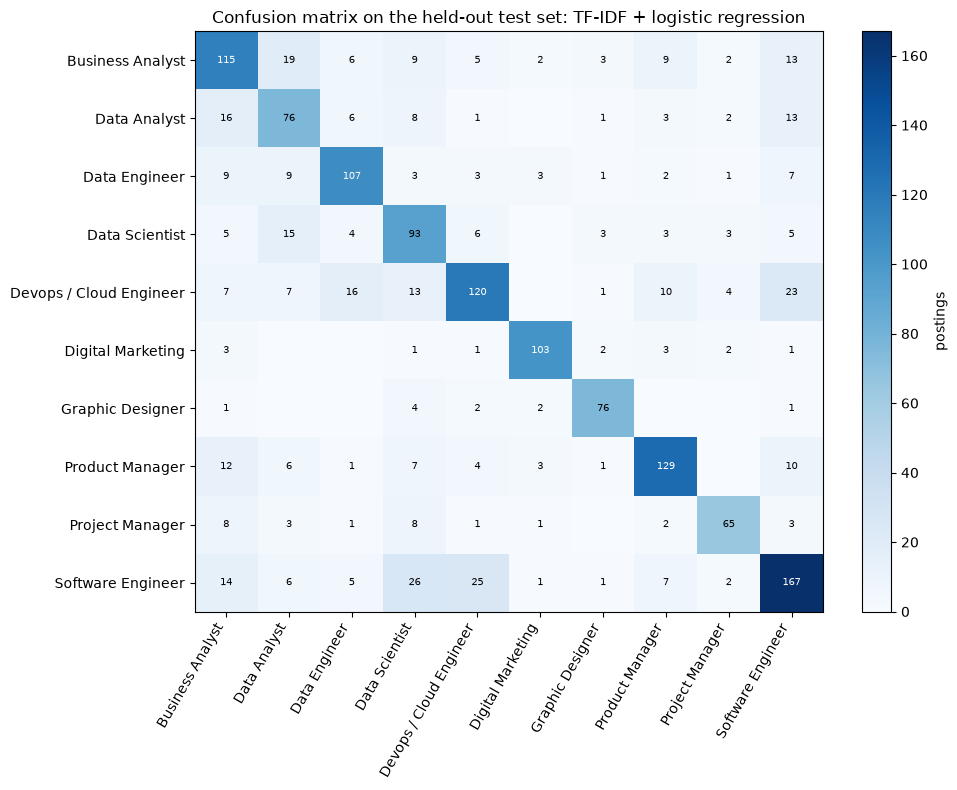

In [381]:
predicted = fitted[selected].predict(texts_test)
roles = sorted(df["role"].unique())

per_role = pd.DataFrame(classification_report(y_test, predicted, labels=roles, output_dict=True, zero_division=0)).T
per_role.round(3).to_csv(OUT / "classification_per_role.csv")
display(per_role.loc[roles, ["precision", "recall", "f1-score", "support"]].round(3))

matrix = pd.DataFrame(confusion_matrix(y_test, predicted, labels=roles), index=roles, columns=roles)
matrix.to_csv(OUT / "classification_confusion_matrix.csv")
heatmap(matrix, f"Confusion matrix on the held-out test set: {selected}", "postings",
        OUT / "08_classification_confusion_matrix.png", "Blues", (10, 8), min_label=1)

## 11. Save outputs

`data/review2/skill_demand.csv` is read by other notebooks and must keep the columns
`skill, frequency, pct_postings, rank` with exactly the 20 skills of the config, ranked 1 to 20.

In [382]:
contract = demand[["skill", "frequency", "pct_postings", "rank"]]
assert len(contract) == 20 and set(contract["skill"]) == set(skills)
assert contract["rank"].tolist() == list(range(1, 21)) and contract["frequency"].is_monotonic_decreasing
contract.to_csv(ROOT / "data" / "review2" / "skill_demand.csv", index=False)

In [383]:
with open(ROOT / "models" / "text_mining_clusters.pkl", "wb") as fh:
    pickle.dump({"vectorizer": vec, "svd": svd, "scale_to_unit_length": SCALE_TO_UNIT, "kmeans": km,
                 "token_pattern": TOKEN_PATTERN, "stop_words": STOP_WORDS, "k": K, "seed": SEED}, fh)

json.dump({"seed": SEED, "rows": N, "pipeline": f"TF-IDF -> TruncatedSVD({SVD_DIMS})" + (" -> unit length" if SCALE_TO_UNIT else "") + " -> K-Means", "k": K,
           "final": final, "baseline": baseline},
          open(OUT / "cluster_run.json", "w"), indent=2)
print("saved: skill_demand.csv, text_mining_clusters.pkl, cluster_run.json")

saved: skill_demand.csv, text_mining_clusters.pkl, cluster_run.json


The dashboard shows the selected classifier, the skill patterns and the predictions on the held-out test
postings, so those are saved too. The classifier was fitted on the training part only, and only test postings
are shown as examples.

In [384]:
import joblib

model = fitted[selected]
assert hasattr(model, "predict_proba"), "the dashboard needs class probabilities"
joblib.dump(model, ROOT / "models" / "text_mining_classifier.joblib")
json.dump(PATTERNS, open(ROOT / "models" / "text_mining_skill_patterns.json", "w"), indent=1)

test_predictions = pd.DataFrame(model.predict_proba(texts_test), columns=model.classes_)
test_predictions.insert(0, "predicted", model.predict(texts_test))
test_predictions.insert(0, "job_id", df["job_id"].iloc[test_rows].values)
test_predictions.to_csv(OUT / "classification_test_predictions.csv", index=False)
print(f"saved classifier, skill patterns and {len(test_predictions):,} test predictions")

saved classifier, skill patterns and 1,513 test predictions


In [385]:
print("Most mentioned skills (postings):", demand.head(5).set_index("skill")["frequency"].to_dict())
print(f"Postings with no listed skill: {100 * (n_found == 0).mean():.1f}%")
display(pd.DataFrame({"size": summary["size"].values, "top_role": share.idxmax(axis=1).values,
                      "top_role_%": share.max(axis=1).round(0).values}, index=share.index))
print(f"Two largest clusters hold {100 * summary['size'].nlargest(2).sum() / N:.0f}% of postings")

Most mentioned skills (postings): {'Machine Learning': 381, 'AWS': 335, 'Python': 296, 'SQL': 290, 'Azure': 254}
Postings with no listed skill: 76.8%


,size,top_role,top_role_%
cluster,,,
0,448,Product Manager,76.0
1,507,Digital Marketing,93.0
2,810,Software Engineer,17.0
3,728,Software Engineer,85.0
4,527,Business Analyst,76.0
5,360,Graphic Designer,96.0
6,636,Software Engineer,26.0
7,1144,Software Engineer,25.0
8,156,Software Engineer,54.0


Two largest clusters hold 30% of postings


## 12. Interpretation for the business objective, and limits

The text-mining objective was narrowed after the 500-character limit was found (see the intro). It
contributes to the project goals as follows: a ranking of skills (not market shares) for employer demand,
and wording evidence for each role.

**Employer demand for skills**
- Machine Learning, AWS, Python, SQL and Azure are mentioned most. The order is the same when only distinct
  descriptions are counted.
- Machine Learning ranks first because the patterns count the abbreviation "ML".
- Read the list as an order, not as market shares. The postings are cut at 500 characters and most mention
  none of the 20 skills, so every percentage is a lower bound.
- Lemmatised text loses some skills (AWS, Kubernetes), so counts must come from the raw text.

**Skills and wording of each role**
- Clustering on wording alone recovers seven roles: Graphic Designer, Digital Marketing, DevOps / Cloud,
  Software Engineer, Project Manager, Product Manager and Business Analyst each dominate one cluster. So
  job descriptions carry role-specific language for these roles.
- Data Scientist, Data Analyst and Data Engineer overlap with each other and with Software Engineer. They are
  also the hardest roles for the classifier below.
- Several clusters are company introductions with no role content (the largest ones mix many roles).
- Skill-rich clusters are DevOps / Cloud and the data cluster. Business and design clusters mention few
  listed skills because the skill list is technical.

**Predicting the role from the description (classification)**
- TF-IDF with logistic regression predicts the role of postings from employers it has never seen: macro
  precision 0.73, recall 0.72, F1 0.72, accuracy 0.71 on a held-out test of 1,513 postings. Always guessing the
  most common role gives F1 0.03 and accuracy 0.17.
- Graphic Designer (F1 0.89) and Digital Marketing (0.88) are easiest. Business Analyst, Data Analyst and
  Data Scientist (about 0.60) are hardest. The largest confusions are Software Engineer with Data Scientist
  (27 postings), DevOps / Cloud with Software Engineer (24) and Business Analyst with Data Analyst (21).
- The linear SVM scores the same as logistic regression (F1 0.72). The scaled-SVD variant scores 0.70 and
  complement naive Bayes 0.67.

**Method choices that matter**
- Plain SVD did not improve on TF-IDF. Scaling the SVD output to unit length did: NMI 0.42 over 5 seeds
  against 0.35, with much more stable clusters (0.82 against 0.61).
- The final K-Means beats Ward and a Gaussian mixture on NMI, ARI, silhouette and the smallest cluster. Ward
  is the only method more stable, and it has a lower NMI.
- The result does not depend on the vectorizer settings (NMI 0.39 to 0.41 over the grid).
- LDA and NMF give similar topics. K = 4 has the lowest LDA perplexity, K = 6 agrees better with role.

**Skill gaps**
- A gap needs a reliable skill profile per role. A 500-character snippet does not give one, so skill gaps
  are not claimed. This is the main reason the objective was narrowed.

**Limits**
1. Counts are lower bounds. Most postings mention none of the 20 skills, and descriptions are cut at 500 characters.
2. The role label comes from the job title, not from a person, and it helped choose K. The held-out test
   (section 6.9) reduces the optimism but does not remove it.
3. Validation labels for the skill patterns come from an AI assistant. The holdout has no "excel" verb or
   "spark" noun, so it does not test those two rules.
4. The classification test is a single split of 1,513 postings with no confidence interval, and the role
   labels come from job titles. Scores measure agreement with those labels.
5. Postings cover India over about three months. Topic names are our reading of the top words. "datum" in
   the topics comes from the lemmatiser turning "data" into "datum".